---
title: "L3-07 · Expectation and variance"
short_title: "Expectation and variance"
subtitle: "The expectation is the balance point of a distribution and the variance is its average squared distance from that point; averaging n independent draws keeps the balance point and divides the variance by n."
description: "Compute the expectation, variance and standard deviation of a finite distribution, use linearity of expectation and the variance rules for independent sums, and explain why the mean of many independent draws concentrates without treating the mean as a certain outcome."
tags: [level-3, coursebook]
---

(lesson-l3-07)=

:::{div}
:class: qcai-meta
![Level 3 icon](../../_static/icons/qicon-level-3.svg) **Level 3 · High-school bridge** · about 90 minutes  
**Big idea.** The expectation is the balance point of a distribution and the variance is its average squared distance from that point; averaging n independent draws keeps the balance point and divides the variance by n.  
**Before this lesson.** [L2-04](#lesson-l2-04), [L3-05](#lesson-l3-05)  
**Lab.** [Chance and repeated trials](../../labs/01-chance.ipynb)
:::

## What you will be able to do

- Compute $E[X]$, $\operatorname{Var}(X)$ and $\sigma$ for a finite distribution, both from the definition and from $E[X^2] - \mu^2$.
- Use linearity of expectation (no independence needed) and $\operatorname{Var}(aX + b) = a^2\operatorname{Var}(X)$.
- Prove that variances add for independent variables and that the mean of $n$ independent draws has variance $\sigma^2/n$, and say what fails when draws share a common cause.
- Apply Chebyshev's inequality to bound the chance that a sample mean is far from the expectation.

## Why this matters

A game pays 0, 1, 2 or 4 points with chances 0.1, 0.4, 0.3 and 0.2. Its average payout is 1.8 points, yet no single play ever pays 1.8. What does that number mean, and how far from it should you expect to land? Two numbers answer these questions: the expectation, where the distribution balances, and the variance, how widely it spreads.

Every estimate in science and machine learning is an average of noisy measurements, including the quantum expectation values of [L3-05](#lesson-l3-05), which are estimated by repeating a measurement on many fresh copies. How quickly that average settles down depends on the variance and on whether the measurements are independent. Get the independence wrong, for example when readings share a slow drift, and more data helps far less than the textbook formula promises.

:::{dropdown} Key terms

**Random variable**
: A quantity $X$ whose value is decided by chance; here it takes finitely many values $x$ with probabilities $p(x) = P(X = x)$.

**Expectation**
: $E[X] = \sum_x x\,p(x)$, the probability-weighted average, also written $\mu$.

**Variance**
: $\operatorname{Var}(X) = E[(X - \mu)^2]$, the average squared distance from the mean, in squared units.

**Standard deviation**
: $\sigma = \sqrt{\operatorname{Var}(X)}$, a typical distance from the mean, in the units of $X$.

**Independent**
: $X$ and $Y$ are independent if $P(X = x, Y = y) = P(X = x)\,P(Y = y)$ for all values.

**Sample mean**
: $\bar X_n = \frac1n(X_1 + \dots + X_n)$, the average of $n$ draws.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l3_07 as _lessonfigs

## The mean as a balance point

:::{prf:definition} Expectation
:label: def-l3-07-expectation
Let $X$ take the values $x$ with probabilities $p(x) \ge 0$, $\sum_x p(x) = 1$. The **expectation** (mean) of $X$ is $E[X] = \sum_x x\,p(x)$, often written $\mu$. For a function $h$, $E[h(X)] = \sum_x h(x)\,p(x)$ [@openstax_expected].
:::

$$
E[X] = 0(0.1) + 1(0.4) + 2(0.3) + 4(0.2) = 1.8
$$ (eq-l3-07-mean)

:::{figure} ../../_static/animations/l3_07_seesaw_mean.mp4
:alt: Four weights of sizes 0.1, 0.4, 0.3 and 0.2 stand on a beam at positions 0, 1, 2 and 4. A fulcrum slides under the beam, which tilts one way and then the other, and balances when the fulcrum is at 1.8.
:width: 100%

Put weight $p(x)$ at position $x$ on a weightless beam. The beam balances exactly when the support is at the mean, here 1.8, where the net turning effect $\sum_x p(x)(x - c)$ is zero.
:::

:::{dropdown} What the animation shows
Blocks of heights proportional to 0.1, 0.4, 0.3 and 0.2 stand on a beam at positions 0, 1, 2 and 4. A triangular fulcrum starts at $c = 0.80$; the readout $\sum_x p(x)(x - c)$ shows $+1.00$ and the beam tips down on the right. The fulcrum slides to $c = 3.00$, the readout becomes $-1.20$ and the beam tips down on the left. It then slides back to $c = 1.80$, the readout is $+0.00$, and the beam is level. The formula $E[X] = 0(0.1) + 1(0.4) + 2(0.3) + 4(0.2) = 1.8$ appears with the reason: $\sum_x p(x)(x - c) = E[X] - c$, which is zero exactly when $c = E[X]$. A note points out that no single outcome equals 1.8.
:::

The balance condition is a one-line computation: $\sum_x p(x)(x - c) = \sum_x x\,p(x) - c\sum_x p(x) = E[X] - c$. So the deviations from the mean always cancel, $E[X - \mu] = 0$, which is why the spread must be measured some other way.


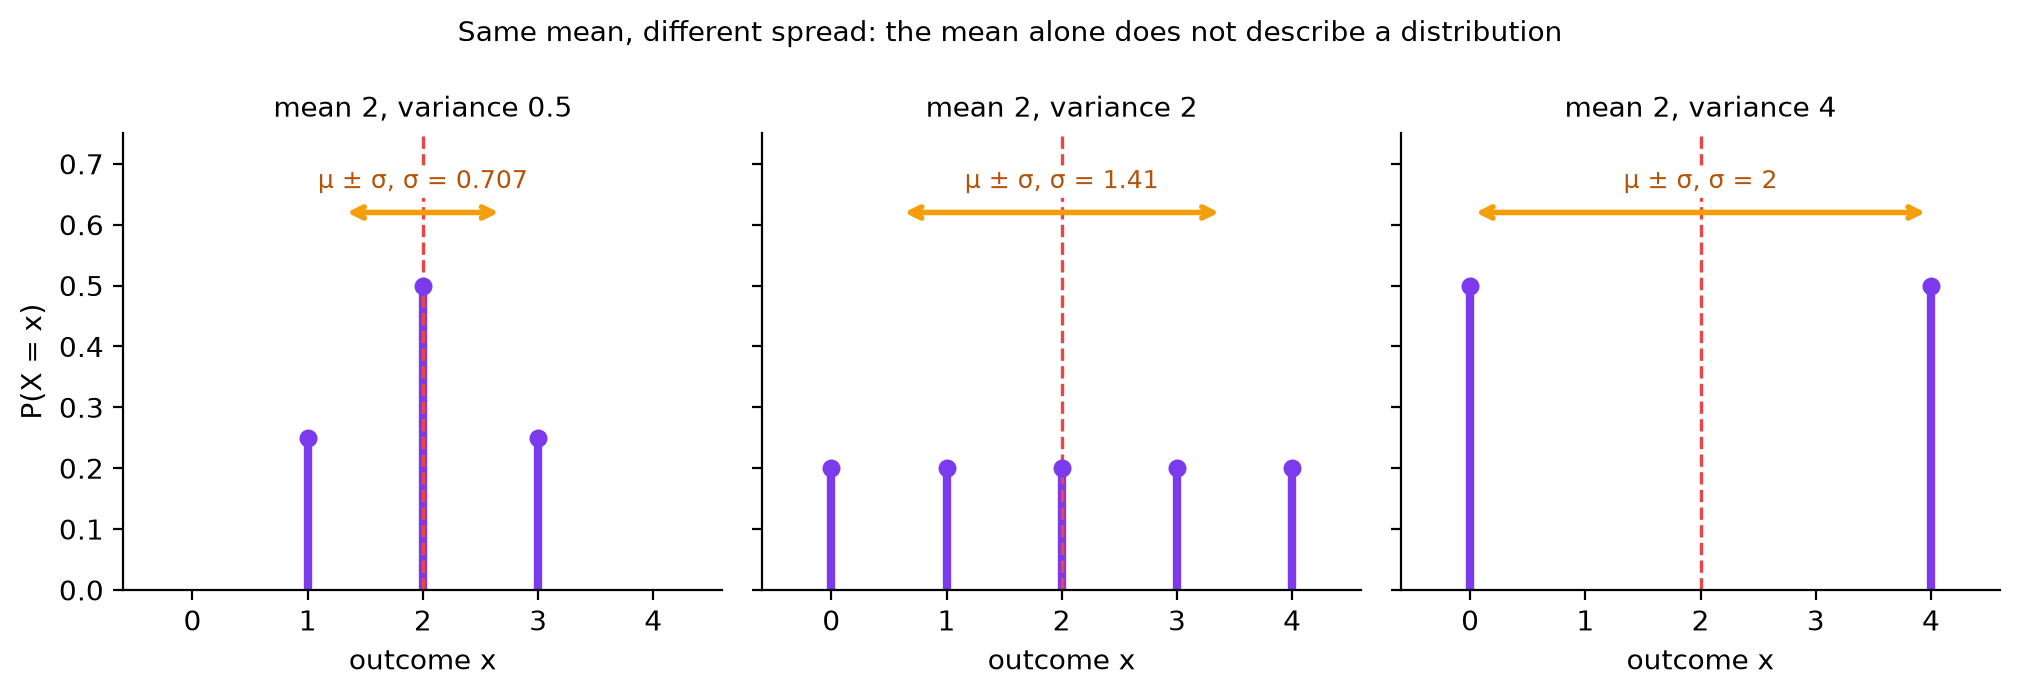

In [2]:
_show_mpl(_lessonfigs.same_mean_spread())

*Three distributions with the same mean 2 and variances 0.5, 2 and 4. The mean says where a distribution balances, not how far its outcomes stray.*

## Variance: average squared distance

:::{prf:definition} Variance and standard deviation
:label: def-l3-07-variance
The **variance** of $X$ is $\operatorname{Var}(X) = E[(X - \mu)^2] = \sum_x (x - \mu)^2 p(x)$, and the **standard deviation** is $\sigma = \sqrt{\operatorname{Var}(X)}$. Squaring stops positive and negative deviations from canceling. Variance has squared units (points squared, meters squared); $\sigma$ has the units of $X$ [@openstax_expected].
:::

:::{prf:proposition} The shortcut formula
:label: prop-l3-07-shortcut
$\operatorname{Var}(X) = E[X^2] - \mu^2$.
:::

:::{prf:proof}
Expand the square and use linearity (proved below): $E[(X - \mu)^2] = E[X^2 - 2\mu X + \mu^2] = E[X^2] - 2\mu E[X] + \mu^2 = E[X^2] - 2\mu^2 + \mu^2 = E[X^2] - \mu^2$.
:::

$$
\operatorname{Var}(X) = 0.324 + 0.256 + 0.012 + 0.968 = 1.56 = 4.8 - 1.8^2, \qquad \sigma = \sqrt{1.56} \approx 1.249
$$ (eq-l3-07-var)

:::{figure} ../../_static/animations/l3_07_variance_squares.mp4
:alt: Squares drawn on a number line between each outcome and the mean 1.8, shaded by probability, with a table of weighted squared distances summing to 1.56, then the shortcut formula derived and the standard deviation 1.249 marked.
:width: 100%

Each outcome contributes the square of its distance from $\mu = 1.8$, weighted by its probability. The four contributions add to 1.56; the shortcut $E[X^2] - \mu^2$ gives the same number.
:::

:::{dropdown} What the animation shows
A number line from 0 to 4 has a dashed red line at $\mu = 1.8$. For each outcome a square is drawn between the outcome and the mean, with side equal to the distance and shading proportional to the probability, and a row of the table appears: $x = 0$: $0.1 \times 3.24 = 0.324$; $x = 1$: $0.4 \times 0.64 = 0.256$; $x = 2$: $0.3 \times 0.04 = 0.012$; $x = 4$: $0.2 \times 4.84 = 0.968$. The sum is $\operatorname{Var}(X) = \sum_x p(x)(x - \mu)^2 = 1.56$. The table is replaced by a derivation that changes term by term: $E[(X - \mu)^2] = E[X^2 - 2\mu X + \mu^2] = E[X^2] - 2\mu E[X] + \mu^2 = E[X^2] - 2\mu^2 + \mu^2 = E[X^2] - \mu^2$, then $= 4.8 - 1.8^2 = 4.8 - 3.24 = 1.56$, and $\sigma = \sqrt{1.56} \approx 1.249$. A bracket marks $\mu \pm \sigma$ on the number line, with the note that variance has squared units while $\sigma$ has the units of $X$.
:::

The outcome 4 is rare (probability 0.2) but far from the mean, and it contributes 0.968, almost two thirds of the variance. Squared distance weights far outcomes heavily; that is a feature when large errors matter most and a weakness when a few wild values should not dominate.

## Rules: linearity and independence

:::{prf:theorem} Linearity of expectation
:label: thm-l3-07-linearity
For random variables $X, Y$ on the same probability space and numbers $a, b, c$: $E[aX + bY + c] = aE[X] + bE[Y] + c$. **No independence is needed.**
:::

:::{prf:proof}
Let $p(x, y) = P(X = x, Y = y)$ be the joint distribution, so that $\sum_y p(x, y) = p_X(x)$ and $\sum_x p(x, y) = p_Y(y)$. Then $E[aX + bY + c] = \sum_{x, y}(ax + by + c)\,p(x, y) = a\sum_x x\sum_y p(x, y) + b\sum_y y\sum_x p(x, y) + c\sum_{x, y}p(x, y) = aE[X] + bE[Y] + c$. Nothing about how $X$ and $Y$ are related was used.
:::

:::{prf:proposition} Shifting and scaling
:label: prop-l3-07-scale
$\operatorname{Var}(aX + b) = a^2\operatorname{Var}(X)$, so the standard deviation becomes $|a|\sigma$.
:::

:::{prf:proof}
$E[aX + b] = a\mu + b$, so $aX + b - E[aX + b] = a(X - \mu)$ and $\operatorname{Var}(aX + b) = E[a^2(X - \mu)^2] = a^2\operatorname{Var}(X)$. Shifting by $b$ moves the balance point but not the spread.
:::

:::{prf:theorem} Independent variables
:label: thm-l3-07-independent
If $X$ and $Y$ are independent, then $E[XY] = E[X]E[Y]$ and $\operatorname{Var}(X + Y) = \operatorname{Var}(X) + \operatorname{Var}(Y)$.
:::

:::{prf:proof}
Independence means $p(x, y) = p_X(x)\,p_Y(y)$ ([L2-04](#lesson-l2-04)), so $E[XY] = \sum_{x, y} xy\,p_X(x)p_Y(y) = \left(\sum_x x\,p_X(x)\right)\left(\sum_y y\,p_Y(y)\right) = E[X]E[Y]$. For the variance, write $\tilde X = X - \mu_X$ and $\tilde Y = Y - \mu_Y$, which are also independent with mean 0. Then $\operatorname{Var}(X + Y) = E[(\tilde X + \tilde Y)^2] = E[\tilde X^2] + 2E[\tilde X\tilde Y] + E[\tilde Y^2]$, and the middle term is $2E[\tilde X]E[\tilde Y] = 0$.
:::

:::{warning} Where independence matters
In general $\operatorname{Var}(X + Y) = \operatorname{Var}(X) + \operatorname{Var}(Y) + 2\operatorname{Cov}(X, Y)$ with $\operatorname{Cov}(X, Y) = E[(X - \mu_X)(Y - \mu_Y)]$. For $Y = X$ the covariance is $\operatorname{Var}(X)$ and $\operatorname{Var}(2X) = 4\operatorname{Var}(X)$, not $2\operatorname{Var}(X)$. Linearity of expectation, by contrast, never needs independence.
:::

## Averages of many draws

:::{prf:corollary} Variance of a sample mean
:label: cor-l3-07-mean
If $X_1, \dots, X_n$ are independent and each has mean $\mu$ and variance $\sigma^2$, then $E[\bar X_n] = \mu$ and $\operatorname{Var}(\bar X_n) = \sigma^2/n$, so the standard deviation of the mean is $\sigma/\sqrt n$.
:::

:::{prf:proof}
By linearity, $E[\bar X_n] = \frac1n\sum_i E[X_i] = \mu$. By the scaling rule and additivity for independent variables (applied $n - 1$ times), $\operatorname{Var}(\bar X_n) = \frac{1}{n^2}\operatorname{Var}\left(\sum_i X_i\right) = \frac{1}{n^2} \cdot n\sigma^2 = \frac{\sigma^2}{n}$.
:::

:::{figure} ../../_static/animations/l3_07_sample_means.mp4
:alt: Histograms of the exact distribution of the average of n fair die rolls for n = 1, 2, 4, 16 and 64, narrowing around 3.5, with the spread sigma over root n shown.
:width: 100%

The exact distribution of the mean of $n$ fair die rolls for $n = 1, 2, 4, 16, 64$. The center stays at 3.5 and the width shrinks like $\sigma/\sqrt n$, with $\sigma = \sqrt{35/12} \approx 1.708$.
:::

:::{dropdown} What the animation shows
Axes show the mean of $n$ rolls from 0.5 to 6.5 and probability per unit of the mean from 0 to 2, with a dashed red line at 3.5. The distributions are exact, computed by convolution, not simulated. For $n = 1$ the histogram is flat at height $1/6$ from 1 to 6 and the readout gives $\sigma/\sqrt n = 1.708$, with $\sigma = \sqrt{35/12} \approx 1.708$. For $n = 2$ it becomes a triangle; for $n = 4$ a rounded hump; for $n = 16$ a narrow bell with $\sigma/\sqrt n = 0.427$; for $n = 64$ a tall spike about 1.9 high with $\sigma/\sqrt n = 0.213$. A bracket above each histogram shows mean $\pm\,\sigma/\sqrt n$. The closing formula is $\operatorname{Var}(\bar X_n) = \sigma^2/n$, valid for independent rolls.
:::

:::{prf:theorem} Chebyshev's inequality
:label: thm-l3-07-chebyshev
For any random variable with mean $\mu$ and variance $\sigma^2$ and any $\varepsilon > 0$: $P(|X - \mu| \ge \varepsilon) \le \sigma^2/\varepsilon^2$. For an independent sample mean, $P(|\bar X_n - \mu| \ge \varepsilon) \le \sigma^2/(n\varepsilon^2)$, which tends to 0 as $n$ grows (the weak law of large numbers).
:::

:::{prf:proof}
Every outcome with $|x - \mu| \ge \varepsilon$ has $(x - \mu)^2/\varepsilon^2 \ge 1$, and every other term is nonnegative, so $P(|X - \mu| \ge \varepsilon) = \sum_{|x - \mu| \ge \varepsilon} p(x) \le \sum_{|x - \mu| \ge \varepsilon} \frac{(x - \mu)^2}{\varepsilon^2}\,p(x) \le \frac{1}{\varepsilon^2}\sum_x (x - \mu)^2 p(x) = \frac{\sigma^2}{\varepsilon^2}$. Apply it to $\bar X_n$, whose variance is $\sigma^2/n$.
:::


In [3]:
_show(_lessonfigs.bernoulli_means())

**Explore.** Each draw is 1 with probability 0.25 and 0 otherwise ($\mu = 0.25$, $\sigma^2 = 0.1875$). Slide $n$ to see the exact distribution of the sample mean tighten around 0.25, and its spread $\sigma/\sqrt n$ fall on the right.

:::{dropdown} What the figure shows
The first panel is a bar chart of the exact (binomial) distribution of the mean of $n$ independent 0/1 draws with $P(1) = 0.25$, for $n = 1, 2, 4, 8, 16, 32, 64, 128$, with a dashed line at the expectation 0.25 and an orange bar showing mean $\pm\,\sigma/\sqrt n$. For $n = 1$ there are two bars, 0.75 at 0 and 0.25 at 1; by $n = 128$ the bars form a narrow bell centered at 0.25 (the probability axis rescales at each step so the shape stays visible). The second panel plots $\sigma/\sqrt n = 0.433/\sqrt n$ against $n$ on a logarithmic axis, from 0.433 at $n = 1$ to about 0.038 at $n = 128$, with a marker at the chosen $n$.
:::

```{mermaid}
graph TD
  D["shared drift D"] --> X1["reading 1"]
  D --> X2["reading 2"]
  D --> X3["reading n"]
  N1["own noise 1"] --> X1
  N2["own noise 2"] --> X2
  N3["own noise n"] --> X3
```

*When every reading shares a common cause (a drift $D$), the readings are correlated and averaging cannot remove $D$. With pairwise correlation $\rho$, $\operatorname{Var}(\bar X_n) = \sigma^2(1 + (n - 1)\rho)/n$, which levels off at $\rho\sigma^2$ instead of falling to 0.*

## Compute it

Exact arithmetic for the running distribution and for dice, including a check of linearity and of variance additivity by enumerating all 36 outcomes of two dice.


In [4]:
import itertools
from fractions import Fraction as Fr
import numpy as np

# the running distribution: P(X = 0, 1, 2, 4) = 0.1, 0.4, 0.3, 0.2
xs = np.array([0, 1, 2, 4])
ps = np.array([0.1, 0.4, 0.3, 0.2])
mu = xs @ ps
ex2 = (xs ** 2) @ ps
print('E[X] =', round(mu, 6), '  E[X^2] =', round(ex2, 6))
print('Var by definition  :', round(((xs - mu) ** 2) @ ps, 6), '  terms', (((xs - mu) ** 2) * ps).round(3))
print('Var by E[X^2]-mu^2 :', round(ex2 - mu ** 2, 6), '  sigma =', round(np.sqrt(ex2 - mu ** 2), 4))

# a fair die, exactly
die = range(1, 7)
mu_d = sum(Fr(k, 6) for k in die)
var_d = sum(Fr(k * k, 6) for k in die) - mu_d ** 2
print('die: mean', mu_d, ' variance', var_d, ' sigma', round(float(var_d) ** 0.5, 4))

# two dice: enumerate all 36 equally likely outcomes
pairs = list(itertools.product(die, die))
S = [a + b for a, b in pairs]
ES = Fr(sum(S), 36)
VS = Fr(sum(s * s for s in S), 36) - ES ** 2
print('sum of two independent dice: mean', ES, ' variance', VS, ' (2 x 35/12 =', 2 * var_d, ')')

# X + X: linearity of expectation still holds, additivity of variance does not
T = [2 * a for a, b in pairs]
ET = Fr(sum(T), 36)
VT = Fr(sum(t * t for t in T), 36) - ET ** 2
print('X + X: mean', ET, ' variance', VT, ' = 4 x 35/12 =', 4 * var_d)

E[X] = 1.8   E[X^2] = 4.8
Var by definition  : 1.56   terms [0.324 0.256 0.012 0.968]
Var by E[X^2]-mu^2 : 1.56   sigma = 1.249
die: mean 7/2  variance 35/12  sigma 1.7078
sum of two independent dice: mean 7  variance 35/6  (2 x 35/12 = 35/6 )
X + X: mean 7  variance 35/3  = 4 x 35/12 = 35/3


Seeded simulations: the spread of sample means against $\sigma/\sqrt n$, Chebyshev's bound against the simulated frequency, correlated readings sharing a drift, and the two variance conventions in NumPy.


In [5]:
rng = np.random.default_rng(2024)
sigma = float(var_d) ** 0.5

# simulated sample means of n die rolls (20000 repetitions each)
for n in (1, 4, 16, 64):
    means = rng.integers(1, 7, size=(20000, n)).mean(axis=1)
    print(f'n = {n:>2}: average of the means {means.mean():.4f}, spread {means.std():.4f}, sigma/sqrt(n) {sigma / np.sqrt(n):.4f}')

# Chebyshev's bound against the simulated frequency, n = 16, distance 1
n = 16
means = rng.integers(1, 7, size=(200000, n)).mean(axis=1)
print('P(|mean - 3.5| >= 1): simulated', round(float(np.mean(np.abs(means - 3.5) >= 1)), 4),
      ' Chebyshev bound', round(float(var_d) / n, 4))

# a shared drift: every reading shares D, so readings are correlated (rho = 0.2, sigma^2 = 1)
rho, n, reps = 0.2, 100, 20000
D = rng.normal(0, np.sqrt(rho), size=(reps, 1))
e = rng.normal(0, np.sqrt(1 - rho), size=(reps, n))
m = (D + e).mean(axis=1)
print('Var of the mean of 100 correlated readings:', round(float(m.var()), 4),
      ' formula (1 + 99 rho)/100 =', round((1 + (n - 1) * rho) / n, 4), ' independent formula 1/100 =', 1 / n)

# population versus sample variance of a data set
data = rng.integers(1, 7, size=10)
print('data', data, ' np.var (divide by n):', round(float(np.var(data)), 4), ' ddof=1 (divide by n - 1):', round(float(np.var(data, ddof=1)), 4))

n =  1: average of the means 3.5028, spread 1.7104, sigma/sqrt(n) 1.7078
n =  4: average of the means 3.4995, spread 0.8528, sigma/sqrt(n) 0.8539
n = 16: average of the means 3.4964, spread 0.4286, sigma/sqrt(n) 0.4270
n = 64: average of the means 3.5020, spread 0.2140, sigma/sqrt(n) 0.2135
P(|mean - 3.5| >= 1): simulated 0.0227  Chebyshev bound 0.1823
Var of the mean of 100 correlated readings: 0.2063  formula (1 + 99 rho)/100 = 0.208  independent formula 1/100 = 0.01
data [2 3 3 3 3 4 1 6 1 3]  np.var (divide by n): 1.89  ddof=1 (divide by n - 1): 2.1


:::{prf:remark} Population variance and sample variance
This lesson's $\operatorname{Var}(X)$ is a property of a known distribution. For a list of data $x_1, \dots, x_n$, `np.var` divides the summed squared deviations by $n$ (`ddof=0`); with `ddof=1` it divides by $n - 1$, which makes it an unbiased estimate of an unknown $\sigma^2$. Estimation is the subject of [L3-10](#lesson-l3-10).
:::

## Worked example

:::{admonition} One die, two dice, sixteen dice
:class: tip

For a fair six-sided die find $E[X]$, $\operatorname{Var}(X)$ and $\sigma$. Then find the mean and variance of the sum of two independent dice, the standard deviation of the average of 16 independent rolls, and Chebyshev's bound on the chance that this average is at least 1 away from 3.5.

1. Mean: $E[X] = \frac{1 + 2 + \dots + 6}{6} = \frac{21}{6} = 3.5$.
2. Second moment: $E[X^2] = \frac{1 + 4 + 9 + 16 + 25 + 36}{6} = \frac{91}{6}$. Variance: $\frac{91}{6} - \frac{49}{4} = \frac{182 - 147}{12} = \frac{35}{12} \approx 2.917$, so $\sigma = \sqrt{35/12} \approx 1.708$.
3. Two dice: by linearity the mean of the sum is $3.5 + 3.5 = 7$; by independence the variance is $\frac{35}{12} + \frac{35}{12} = \frac{35}{6} \approx 5.833$.
4. Average of 16 rolls: mean 3.5 and standard deviation $\sigma/\sqrt{16} = 1.708/4 \approx 0.427$.
5. Chebyshev: $P(|\bar X_{16} - 3.5| \ge 1) \le \frac{35/12}{16 \cdot 1^2} = \frac{35}{192} \approx 0.182$. The true chance is far smaller (the second code cell finds about 0.02); Chebyshev is a guarantee for every distribution, so it is usually loose.

**Result.** One die: $\mu = 3.5$, $\sigma^2 = 35/12$, $\sigma \approx 1.708$. Two dice: mean 7, variance $35/6$. Sixteen-roll average: standard deviation about 0.427, and at most an 18.2 percent chance of landing 1 or more from 3.5.
:::

## Exercises

**1. (Core)** $X$ takes the values $-1$ and $1$ with probability $1/2$ each. Find $E[X]$, $E[X^2]$ and $\operatorname{Var}(X)$. Is $E[X]$ a possible value of $X$?

:::{dropdown} Solution
$E[X] = (-1)\tfrac12 + (1)\tfrac12 = 0$. Both squares equal 1, so $E[X^2] = 1$ and $\operatorname{Var}(X) = 1 - 0^2 = 1$, $\sigma = 1$. The mean 0 is not a possible value: every draw is $-1$ or $1$.
:::

**2. (Core)** $X$ is 1 with probability 0.25 and 0 otherwise. Find $E[X]$, $\operatorname{Var}(X)$ and $\sigma$.

:::{dropdown} Solution
$E[X] = 0.25$. Since $X^2 = X$ for 0/1 values, $E[X^2] = 0.25$ and $\operatorname{Var}(X) = 0.25 - 0.25^2 = 0.1875$, so $\sigma = \sqrt{0.1875} \approx 0.433$. Most single draws (75 percent) return 0.
:::

**3. (Stretch)** For the running distribution ($\mu = 1.8$, $\operatorname{Var}(X) = 1.56$), a payout rule is $Y = 3X + 2$. Find $E[Y]$, $\operatorname{Var}(Y)$ and the standard deviation of $Y$ without listing the values of $Y$.

:::{dropdown} Solution
$E[Y] = 3(1.8) + 2 = 7.4$. $\operatorname{Var}(Y) = 3^2 \cdot 1.56 = 14.04$. Standard deviation $= 3 \times 1.249 \approx 3.747$ (equivalently $\sqrt{14.04}$). The added 2 changes the mean but not the spread.
:::

**4. (Stretch)** Show that $\operatorname{Var}(X + Y) = \operatorname{Var}(X) + \operatorname{Var}(Y) + 2\operatorname{Cov}(X, Y)$. Use it to compute $\operatorname{Var}(X + X)$ and $\operatorname{Var}(X - X)$ and explain why independence fails here.

:::{dropdown} Solution
With $\tilde X = X - \mu_X$ and $\tilde Y = Y - \mu_Y$: $E[(\tilde X + \tilde Y)^2] = E[\tilde X^2] + 2E[\tilde X\tilde Y] + E[\tilde Y^2] = \operatorname{Var}(X) + 2\operatorname{Cov}(X, Y) + \operatorname{Var}(Y)$. For $Y = X$, $\operatorname{Cov}(X, X) = \operatorname{Var}(X)$, so $\operatorname{Var}(X + X) = 4\operatorname{Var}(X)$. For $Y = -X$, $\operatorname{Cov}(X, -X) = -\operatorname{Var}(X)$, so $\operatorname{Var}(X - X) = 0$, as it must be for the constant 0. $X$ is not independent of itself: knowing one copy fixes the other.
:::

**5. (Challenge)** A binomial count $K$ is the number of successes in $n$ independent trials, each a success with probability $p$. Write $K$ as a sum of 0/1 indicators and prove $E[K] = np$ and $\operatorname{Var}(K) = np(1 - p)$. Which of the two results needs independence?

:::{dropdown} Solution
$K = I_1 + \dots + I_n$ with $I_j = 1$ if trial $j$ succeeds. Each $I_j$ has $E[I_j] = p$ and, since $I_j^2 = I_j$, $\operatorname{Var}(I_j) = p - p^2 = p(1 - p)$. Linearity gives $E[K] = np$, with no independence needed. Independence of the trials gives $\operatorname{Var}(K) = \sum_j \operatorname{Var}(I_j) = np(1 - p)$. Dividing by $n$: the sample proportion has mean $p$ and variance $p(1 - p)/n$; for $p = 0.25$ this is $0.1875/n$, as in the interactive figure.
:::

**6. (Challenge)** Readings $X_1, \dots, X_n$ each have variance $\sigma^2$, and every pair has correlation $\rho \ge 0$, that is $\operatorname{Cov}(X_i, X_j) = \rho\sigma^2$ for $i \ne j$. Show $\operatorname{Var}(\bar X_n) = \sigma^2(1 + (n - 1)\rho)/n$. What happens as $n \to \infty$? Evaluate for $\rho = 0.2$, $n = 100$, $\sigma^2 = 1$.

:::{dropdown} Solution
$\operatorname{Var}\left(\sum_i X_i\right) = \sum_i \operatorname{Var}(X_i) + \sum_{i \ne j}\operatorname{Cov}(X_i, X_j) = n\sigma^2 + n(n - 1)\rho\sigma^2$. Divide by $n^2$: $\operatorname{Var}(\bar X_n) = \sigma^2(1 + (n - 1)\rho)/n$. As $n \to \infty$ this tends to $\rho\sigma^2$, not 0: the shared part never averages away. For $\rho = 0.2$, $n = 100$: $(1 + 99 \cdot 0.2)/100 = 20.8/100 = 0.208$, about 21 times the independent value $0.01$; the second code cell reproduces this.
:::

## Check your understanding

**1. $P(X = 0, 1, 2, 4) = 0.1, 0.4, 0.3, 0.2$. What is $E[X]$?**

- **A.** 1
- **B.** 2
- **C.** 1.75
- **D.** 1.8

:::{dropdown} Show the answer
**D. 1.8**

$E[X] = 0(0.1) + 1(0.4) + 2(0.3) + 4(0.2) = 0.4 + 0.6 + 0.8 = 1.8$. The unweighted average of the values, 1.75, ignores the probabilities.
:::

**2. Which quantity always has the squared units of the outcome?**

- **A.** The variance
- **B.** The standard deviation
- **C.** The expectation

:::{dropdown} Show the answer
**A. The variance**

Variance averages squared deviations, so its units are squared. Its square root, the standard deviation, returns to the units of the outcome, as does the expectation.
:::

**3. $X$ and $Y$ are two measurements that are strongly correlated. Which statement is correct?**

- **A.** Neither rule holds for correlated variables
- **B.** $E[X + Y] = E[X] + E[Y]$ holds only if $X$ and $Y$ are independent
- **C.** $E[X + Y] = E[X] + E[Y]$, but $\operatorname{Var}(X + Y)$ need not equal $\operatorname{Var}(X) + \operatorname{Var}(Y)$
- **D.** Both $E[X + Y] = E[X] + E[Y]$ and $\operatorname{Var}(X + Y) = \operatorname{Var}(X) + \operatorname{Var}(Y)$ hold

:::{dropdown} Show the answer
**C. $E[X + Y] = E[X] + E[Y]$, but $\operatorname{Var}(X + Y)$ need not equal $\operatorname{Var}(X) + \operatorname{Var}(Y)$**

Linearity of expectation holds for any random variables. Variances add only when the covariance is zero, which independence guarantees; in general there is an extra $2\operatorname{Cov}(X, Y)$.
:::

**4. Events $A$ and $B$ are independent with $P(A) = 0.5$ and $P(B) = 0.4$. What is $P(A \text{ and } B)$?** *(Review of [L2-04](#lesson-l2-04))*

- **A.** 0.9
- **B.** 0.1
- **C.** 0.2
- **D.** 0.45

:::{dropdown} Show the answer
**C. 0.2**

For independent events $P(A \text{ and } B) = P(A)P(B) = 0.5 \times 0.4 = 0.2$. The same product rule, applied to every pair of values, gives $E[XY] = E[X]E[Y]$ for independent random variables.
:::

## Common misconceptions

- **"The expected value is the most likely outcome, or at least a possible one."** It is a balance point. For the running example the most likely outcome is 1, while $E[X] = 1.8$ is not a possible outcome at all. The mean of $\{-1, 1\}$ with equal chances is 0, which never occurs.
- **"Variances always add."** They add for independent (more generally, uncorrelated) variables. $\operatorname{Var}(X + X) = 4\operatorname{Var}(X)$ and $\operatorname{Var}(X - X) = 0$. Expectations, by contrast, always add.
- **"With enough data the error of an average always goes to zero like $1/\sqrt n$."** That rate assumes independent draws with a common finite variance. Readings that share a drift or another common cause have $\operatorname{Var}(\bar X_n) \to \rho\sigma^2$, and a systematic bias in every reading is not reduced by averaging at all.

:::{caution} Scope and limits
This lesson treats finite distributions, where every expectation exists; for distributions with infinitely many values the sums may diverge and the mean or variance may not exist. The rate $\sigma/\sqrt n$ and the variance of a sum assume independent draws with a common finite variance; correlated or drifting measurements behave differently, and averaging never removes a bias shared by every reading. Chebyshev's inequality is a worst-case bound; the shape of the sample-mean distribution (approximately normal for large $n$, the central limit theorem) is mentioned but not proved here. The histograms in the animation are exact distributions, while the code cell results are seeded simulations.
:::

:::{seealso} Where this leads
Expectation values of quantum observables ([L3-05](#lesson-l3-05)) are estimated by sample means of measurement outcomes, with error $\sigma/\sqrt n$ for independent shots. Entropy in [L3-08](#lesson-l3-08) is itself an expectation, of $-\log_2 p(X)$. Confidence intervals in [L3-10](#lesson-l3-10) turn $\sigma/\sqrt n$ into a statement about uncertainty, and in Level 4 average causal effects are expectations of differences under intervention.
:::

:::{dropdown} For instructors

**Why this lesson.** Expectation and variance are the language in which every later estimate is reported, from quantum expectation values to average causal effects. The seesaw and the squared-distance pictures make the definitions physical, and the independence conditions in the variance rules are where real data analyses most often go wrong [@openstax_expected; @mml].

**Teaching notes.**

- Run the seesaw with physical weights or coins on a ruler before the animation; students find the balance point by trial and then check $\sum_x x\,p(x)$.
- Ask students to predict the variance of $X + X$ before computing it; most say $2\operatorname{Var}(X)$, which sets up the covariance term.
- Use the interactive figure to read off $\sigma/\sqrt n$ at $n = 4$ and $n = 16$ and observe that quadrupling the data halves the spread.
- Close with the shared-drift diagram and ask what experimental design would make readings closer to independent (fresh preparations, randomized order, recalibration).

**Assessment.** The core exercises check the definitions; the stretch exercises check the scaling and covariance rules; the challenge exercises (binomial variance from indicators, correlated averages) test whether students can decide when independence is needed.

**Going further.** State the central limit theorem and compare the exact distribution for $n = 16$ dice with a normal curve of mean 3.5 and standard deviation 0.427. Cover and Thomas use expectation throughout to define entropy and typical sequences [@coverthomas].

:::

## References

This lesson draws on [@openstax_expected; @openstax; @mml; @coverthomas].

**Further reading.**

- [@openstax_expected]: Section 4.2 computes means and standard deviations of discrete distributions with tables, matching this lesson's examples.
- [@mml]: Chapter 6 covers expectation, variance, covariance and sums of random variables for machine learning.

**Next:** [L3-08 · Entropy and uncertainty](#lesson-l3-08)
